In [2]:
import pandas as pd
import mysql.connector

In [3]:
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="samruddhi",
    database="employee_attrition"
)

print("Database connected successfully!")

Database connected successfully!


In [4]:
emp1=pd.read_sql("select * from emp",conn)
emp1.head()

C:\Users\ACER\AppData\Local\Temp\ipykernel_5556\2909697238.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  emp1=pd.read_sql("select * from emp",conn)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
emp1.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [6]:
emp1.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [7]:
emp1.shape

(1470, 35)

In [8]:
emp1.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [12]:
emp1.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [14]:
emp1.duplicated().sum()


np.int64(0)

In [19]:
#  Check the number of employees who stayed and left.
emp1["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [22]:
# Find the total number of employees.
emp1["EmployeeNumber"].nunique()

1470

In [24]:
#Count employees in each department.
emp1["Department"].value_counts()

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

In [26]:
#Count employees who left the company.
(emp1["Attrition"]=="Yes").sum()

np.int64(237)

In [28]:
#Calculate the attrition rate in percentage.
attrition_rate = (emp1["Attrition"] == "Yes").mean() * 100
round(attrition_rate, 2)

np.float64(16.12)

In [30]:
#Find the number of employees who left in each department.
emp1[emp1["Attrition"]=="Yes"]["Department"].value_counts()

Department
Research & Development    133
Sales                      92
Human Resources            12
Name: count, dtype: int64

In [32]:
#Find the number of employees who left in each job role.
emp1[emp1["Attrition"]=="Yes"]["JobRole"].value_counts()

JobRole
Laboratory Technician        62
Sales Executive              57
Research Scientist           47
Sales Representative         33
Human Resources              12
Manufacturing Director       10
Healthcare Representative     9
Manager                       5
Research Director             2
Name: count, dtype: int64

In [33]:
#Compare attrition by overtime status.
pd.crosstab(emp1["OverTime"], emp1["Attrition"])

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [34]:
#Find the average monthly income in each department.
emp1.groupby("Department")["MonthlyIncome"].mean()

Department
Human Resources           6654.507937
Research & Development    6281.252862
Sales                     6959.172646
Name: MonthlyIncome, dtype: float64

In [36]:
#Compare the average age of employees who stayed and left.
emp1.groupby("Attrition")["Age"].mean()

Attrition
No     37.561233
Yes    33.607595
Name: Age, dtype: float64

In [37]:
# Create a bar chart showing attrition by department.
import matplotlib.pyplot as plt


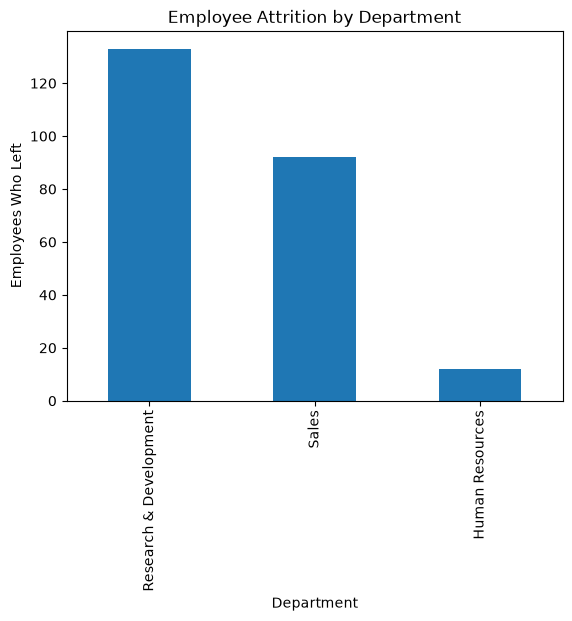

In [38]:

attrition = emp1[emp1["Attrition"] == "Yes"]
department_count = attrition["Department"].value_counts()

department_count.plot(kind="bar")
plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Employees Who Left")
plt.show()

In [41]:
##. Overall attrition rate
round((emp1["Attrition"] == "Yes").mean() * 100, 2)

np.float64(16.12)

In [42]:
# 2. Department-wise attrition count
emp1[emp1["Attrition"] == "Yes"]["Department"].value_counts()

Department
Research & Development    133
Sales                      92
Human Resources            12
Name: count, dtype: int64

In [43]:
# 3. Attrition by overtime
pd.crosstab(emp1["OverTime"], emp1["Attrition"])

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [44]:
 # 4. Attrition by job role
emp1[emp1["Attrition"] == "Yes"]["JobRole"].value_counts()

JobRole
Laboratory Technician        62
Sales Executive              57
Research Scientist           47
Sales Representative         33
Human Resources              12
Manufacturing Director       10
Healthcare Representative     9
Manager                       5
Research Director             2
Name: count, dtype: int64

In [45]:
#  Calculate attrition rate by overtime status.
emp1.groupby("OverTime")["Attrition"].apply(
    lambda x: round((x == "Yes").mean() * 100, 2)
)

OverTime
No     10.44
Yes    30.53
Name: Attrition, dtype: float64

In [46]:
# Q23. Calculate attrition rate by department.
emp1.groupby("Department")["Attrition"].apply(
    lambda x: round((x == "Yes").mean() * 100, 2)
).sort_values(ascending=False)

Department
Sales                     20.63
Human Resources           19.05
Research & Development    13.84
Name: Attrition, dtype: float64

In [47]:
# Q24. Calculate attrition rate by job role.
emp1.groupby("JobRole")["Attrition"].apply(
    lambda x: round((x == "Yes").mean() * 100, 2)
).sort_values(ascending=False)

JobRole
Sales Representative         39.76
Laboratory Technician        23.94
Human Resources              23.08
Sales Executive              17.48
Research Scientist           16.10
Manufacturing Director        6.90
Healthcare Representative     6.87
Manager                       4.90
Research Director             2.50
Name: Attrition, dtype: float64

In [48]:
# Q26. Compare average years at company for employees who stayed and left.
emp1.groupby("Attrition")["YearsAtCompany"].mean().round(2)

Attrition
No     7.37
Yes    5.13
Name: YearsAtCompany, dtype: float64

In [49]:
# Q27. Analyze attrition by age group.
emp1["AgeGroup"] = pd.cut(
    emp1["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

emp1.groupby("AgeGroup", observed=False)["Attrition"].apply(
    lambda x: round((x == "Yes").mean() * 100, 2)
)

AgeGroup
18-25    35.77
26-35    19.14
36-45     9.19
46-55    11.50
56+      17.02
Name: Attrition, dtype: float64

In [50]:
# Q28. Analyze attrition by job satisfaction level.
emp1.groupby("JobSatisfaction")["Attrition"].apply(
    lambda x: round((x == "Yes").mean() * 100, 2)
)

JobSatisfaction
1    22.84
2    16.43
3    16.52
4    11.33
Name: Attrition, dtype: float64

In [51]:
# Q29. Analyze attrition by business travel category.
emp1.groupby("BusinessTravel")["Attrition"].apply(
    lambda x: round((x == "Yes").mean() * 100, 2)
).sort_values(ascending=False)

BusinessTravel
Travel_Frequently    24.91
Travel_Rarely        14.96
Non-Travel            8.00
Name: Attrition, dtype: float64

In [52]:
# Q30. Create a summary of key HR metrics.
summary = pd.Series({
    "Total Employees": emp1["EmployeeNumber"].nunique(),
    "Employees Left": (emp1["Attrition"] == "Yes").sum(),
    "Attrition Rate (%)": round(
        (emp1["Attrition"] == "Yes").mean() * 100, 2
    ),
    "Average Age": round(emp1["Age"].mean(), 2),
    "Average Monthly Income": round(emp1["MonthlyIncome"].mean(), 2),
    "Average Years at Company": round(emp1["YearsAtCompany"].mean(), 2)
})

summary

Total Employees             1470.00
Employees Left               237.00
Attrition Rate (%)            16.12
Average Age                   36.92
Average Monthly Income      6502.93
Average Years at Company       7.01
dtype: float64